# Question 2: Multilayer Perceptron

In [12]:
import random, time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms

NUM_CLASSES   = 10
BATCH_SIZE    = 32
LEARNING_RATE = 5e-4
EPOCHS_T2     = 10
EPOCHS_T3     = 30
N_SMALL       = 5000
SEED          = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("Device:", DEVICE)

Device: cpu


In [13]:
transform = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=transform)
testset  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
testloader  = DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(len(trainset), "training images,", len(testset), "test images")

100%|██████████| 170M/170M [45:36<00:00, 62.3kB/s]


50000 training images, 10000 test images


## Training utilities

`evaluate(model, loader)` returns the average loss and the accuracy (%) without computing gradients. It uses `eval()` mode by default; `use_eval=False` keeps `train()` mode, which is needed for the dropout check in Task 3.

`fit(model, trainloader, testloader, epochs, ...)` trains with Adam and returns the learning curves as a dictionary: the running train loss and accuracy of the demo (computed in `train()` mode), the train loss and accuracy measured again in `eval()` mode after each epoch (`*_eval`), and the test loss and accuracy.

In [14]:
def evaluate(model, loader, criterion=None, use_eval=True):
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
    model.train(not use_eval)
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            correct += outputs.argmax(1).eq(labels).sum().item()
            total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


def fit(model, trainloader, testloader, epochs, lr=LEARNING_RATE, weight_decay=0.0,
        eval_train=True, verbose=True, tag=""):
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    keys = ["train_loss", "train_acc",
            "train_loss_eval", "train_acc_eval",
            "test_loss", "test_acc"]
    hist = {k: [] for k in keys}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in trainloader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            correct += outputs.argmax(1).eq(labels).sum().item()
            total += labels.size(0)
        hist["train_loss"].append(running_loss / total)
        hist["train_acc"].append(100.0 * correct / total)

        if eval_train:
            tl, ta = evaluate(model, trainloader, criterion)
        else:
            tl, ta = float("nan"), float("nan")
        hist["train_loss_eval"].append(tl)
        hist["train_acc_eval"].append(ta)

        te_l, te_a = evaluate(model, testloader, criterion)
        hist["test_loss"].append(te_l)
        hist["test_acc"].append(te_a)

        if verbose:
            print(f"{tag}epoch {epoch:2d}/{epochs}  "
                  f"train(eval-mode) loss={tl:.4f} acc={ta:.2f}%  |  "
                  f"test loss={te_l:.4f} acc={te_a:.2f}%  ({time.time()-t0:.1f}s)")
    return hist


def plot_curves(results, title, fname, mark_epoch=None, mark_label=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = plt.cm.tab10(np.arange(len(results)))
    for (name, h), c in zip(results.items(), colors):
        ep = np.arange(1, len(h["test_loss"]) + 1)
        axes[0].plot(ep, h["train_loss_eval"], "--", color=c, label=f"{name} – train")
        axes[0].plot(ep, h["test_loss"],       "-",  color=c, label=f"{name} – test")
        axes[1].plot(ep, h["train_acc_eval"],  "--", color=c, label=f"{name} – train")
        axes[1].plot(ep, h["test_acc"],        "-",  color=c, label=f"{name} – test")
    if mark_epoch is not None:
        axes[0].axvline(mark_epoch, color="k", ls=":", lw=1.5, label=mark_label)
        axes[1].axvline(mark_epoch, color="k", ls=":", lw=1.5)
    axes[0].set_title("Cross-entropy loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[1].set_title("Accuracy (%)");       axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()
    print("Saved", fname)

## Task 1: Configurable MLP

`MLP(input_size, hidden, num_classes, activation, use_bn, p_drop)` builds a Flatten layer, then for each hidden size a Linear layer, an optional `BatchNorm1d`, the activation and an optional Dropout, and finally the output Linear layer. With `use_bn=True` a `BatchNorm1d` also follows the output layer, so batch norm comes after every linear layer as the assignment says. Dropout is never applied to the output.

`MLP()` uses `hidden=(200, 150)`, ReLU, no batch norm and no dropout, which is the demo network. The cell below compares it with a copy of the demo class: same number of parameters, same initial weights for the same seed, and same outputs.

In [16]:
class MLP(nn.Module):
    def __init__(self, input_size=32*32*3, hidden=(200, 150), num_classes=NUM_CLASSES,
                 activation=nn.ReLU, use_bn=False, p_drop=0.0):
        super().__init__()
        layers = [nn.Flatten()]
        in_features = input_size
        for h in hidden:
            layers.append(nn.Linear(in_features, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(activation())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            in_features = h
        layers.append(nn.Linear(in_features, num_classes))
        if use_bn:
            layers.append(nn.BatchNorm1d(num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class DemoMLP(nn.Module):
    def __init__(self, input_size=32*32*3, hidden1=200, hidden2=150, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.act1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.act2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        return self.fc3(x)


set_seed(0); demo = DemoMLP()
set_seed(0); mine = MLP()
x = torch.randn(8, 3, 32, 32)

assert sum(p.numel() for p in demo.parameters()) == sum(p.numel() for p in mine.parameters())
assert all(torch.equal(a, b) for a, b in zip(demo.parameters(), mine.parameters())), "initial weights differ"
assert torch.allclose(demo(x), mine(x)), "outputs differ"
print("MLP() reproduces the demo network (same parameters, same initial weights, same outputs).")
print("\nDefault MLP():\n", mine)
print("\nMLP(hidden=(200,150), use_bn=True, p_drop=0.3):\n", MLP(use_bn=True, p_drop=0.3))
print("\nMLP(hidden=(512,256,128), activation=nn.Tanh):", MLP(hidden=(512, 256, 128), activation=nn.Tanh).net)

MLP() reproduces the demo network (same parameters, same initial weights, same outputs).

Default MLP():
 MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=200, bias=True)
    (2): ReLU()
    (3): Linear(in_features=200, out_features=150, bias=True)
    (4): ReLU()
    (5): Linear(in_features=150, out_features=10, bias=True)
  )
)

MLP(hidden=(200,150), use_bn=True, p_drop=0.3):
 MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=200, bias=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=200, out_features=150, bias=True)
    (6): BatchNorm1d(150, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=150, out_features=10, bias=True)
    (10)

## Task 2: Batch normalization and dropout

The four models are trained for 10 epochs on the full training set with Adam (learning rate 5e-4, batch size 32), each one starting from the same seed. After every epoch the whole training set is evaluated again in `eval()` mode. The generalization gap is the train accuracy minus the test accuracy after epoch 10.

In [17]:
configs_t2 = {
    "Demo MLP":         dict(),
    "BatchNorm":        dict(use_bn=True),
    "Dropout 0.3":      dict(p_drop=0.3),
    "BatchNorm+Drop":   dict(use_bn=True, p_drop=0.3),
}

results_t2, models_t2 = {}, {}
for name, cfg in configs_t2.items():
    print(f"\n===== {name} =====")
    set_seed(SEED)                                   # same seed for every model
    model = MLP(**cfg).to(DEVICE)
    results_t2[name] = fit(model, trainloader, testloader, EPOCHS_T2, tag=f"[{name}] ")
    models_t2[name] = model


===== Demo MLP =====
[Demo MLP] epoch  1/10  train(eval-mode) loss=1.6862 acc=40.11%  |  test loss=1.6875 acc=39.64%  (45.0s)
[Demo MLP] epoch  2/10  train(eval-mode) loss=1.6074 acc=42.98%  |  test loss=1.6180 acc=42.88%  (50.1s)
[Demo MLP] epoch  3/10  train(eval-mode) loss=1.5586 acc=44.03%  |  test loss=1.5787 acc=43.46%  (50.4s)
[Demo MLP] epoch  4/10  train(eval-mode) loss=1.4752 acc=47.73%  |  test loss=1.5052 acc=46.48%  (48.3s)
[Demo MLP] epoch  5/10  train(eval-mode) loss=1.5122 acc=45.82%  |  test loss=1.5459 acc=44.78%  (49.3s)
[Demo MLP] epoch  6/10  train(eval-mode) loss=1.4301 acc=49.15%  |  test loss=1.4835 acc=46.93%  (49.3s)
[Demo MLP] epoch  7/10  train(eval-mode) loss=1.4095 acc=49.35%  |  test loss=1.4727 acc=47.33%  (48.3s)
[Demo MLP] epoch  8/10  train(eval-mode) loss=1.3799 acc=50.59%  |  test loss=1.4557 acc=48.18%  (49.4s)
[Demo MLP] epoch  9/10  train(eval-mode) loss=1.3298 acc=52.46%  |  test loss=1.4173 acc=49.58%  (49.7s)
[Demo MLP] epoch 10/10  train(eva

Model               Train acc (eval)    Test acc    Gap (pp)   Best test acc
----------------------------------------------------------------------------
Demo MLP                      52.59%      49.86%        2.73          49.86%
BatchNorm                     68.10%      53.87%       14.23          53.87%
Dropout 0.3                   43.23%      42.16%        1.07          42.16%
BatchNorm+Drop                59.93%      53.87%        6.06          53.87%


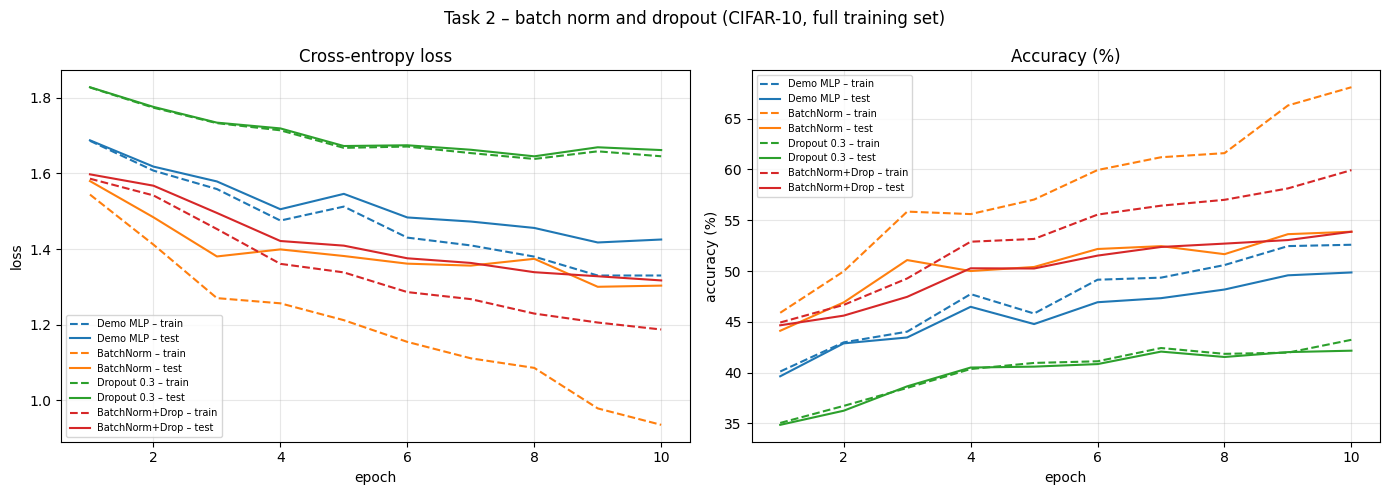

Saved q2_task2_curves.png


In [18]:
print(f"{'Model':<18}{'Train acc (eval)':>18}{'Test acc':>12}{'Gap (pp)':>12}{'Best test acc':>16}")
print("-" * 76)
for name, h in results_t2.items():
    tr, te = h["train_acc_eval"][-1], h["test_acc"][-1]
    print(f"{name:<18}{tr:>17.2f}%{te:>11.2f}%{tr-te:>12.2f}{max(h['test_acc']):>15.2f}%")

plot_curves(results_t2, "Task 2 – batch norm and dropout (CIFAR-10, full training set)", "q2_task2_curves.png")

### Analysis

Train accuracy is measured in `eval()` mode because the running accuracy of the demo is computed while the weights are still changing and, with dropout or batch norm, with a different network from the one used at test time.

| Model | Train acc (eval) | Test acc | Gap (pp) |
|---|---|---|---|
| Demo MLP | 52.59 % | 49.86 % | 2.73 |
| BatchNorm | 68.10 % | 53.87 % | 14.23 |
| Dropout 0.3 | 43.23 % | 42.16 % | 1.07 |
| BatchNorm + Dropout 0.3 | 59.93 % | 53.87 % | 6.06 |

The demo MLP has a small gap (2.73 pp) and is not clearly overfitting after 10 epochs.

Batch norm fits the training set much better (68.10 % against 52.59 %) and raises the test accuracy by 4.0 pp, but the training accuracy grows faster than the test accuracy, so it has the largest gap (14.23 pp). It speeds up optimisation but does not regularise much.

Dropout 0.3 alone has the smallest gap (1.07 pp), but both accuracies are the lowest (43.23 % and 42.16 %), 7.7 pp below the demo on the test set. The small gap comes from under-fitting, not from better generalisation.

With both, dropout lowers the train accuracy from 68.10 % to 59.93 % and the gap from 14.23 to 6.06 pp, while the test accuracy stays at 53.87 %. This is the best trade-off of the four.

Each model was trained once with one seed, so differences of about 1 pp should not be over-interpreted. In particular, BatchNorm and BatchNorm + Dropout have the same test accuracy.

## Task 3: Overfitting on a small data set

The models are trained for 30 epochs on 5,000 randomly drawn training images (fixed seed): plain, dropout 0.5, weight decay 1e-3, and dropout 0.5 with weight decay 1e-3. Weight decay is the `weight_decay` argument of `torch.optim.Adam`. The test set is the full 10,000 images.

In [19]:
g = torch.Generator().manual_seed(SEED)
small_idx = torch.randperm(len(trainset), generator=g)[:N_SMALL].tolist()
small_trainset = Subset(trainset, small_idx)
small_trainloader = DataLoader(small_trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

counts = np.bincount([trainset.targets[i] for i in small_idx], minlength=NUM_CLASSES)
print("Subset size:", len(small_trainset), "| images per class:", counts)

Subset size: 5000 | images per class: [530 483 478 478 493 497 517 518 511 495]


In [20]:
configs_t3 = {
    "Plain":                dict(model=dict(),             wd=0.0),
    "Dropout 0.5":          dict(model=dict(p_drop=0.5),   wd=0.0),
    "Weight decay 1e-3":    dict(model=dict(),             wd=1e-3),
    "Dropout 0.5 + WD":     dict(model=dict(p_drop=0.5),   wd=1e-3),
}

results_t3, models_t3 = {}, {}
for name, cfg in configs_t3.items():
    print(f"\n===== {name} =====")
    set_seed(SEED)
    model = MLP(**cfg["model"]).to(DEVICE)
    results_t3[name] = fit(model, small_trainloader, testloader, EPOCHS_T3,
                           weight_decay=cfg["wd"], tag=f"[{name}] ", verbose=False)
    models_t3[name] = model
    h = results_t3[name]
    print(f"final: train acc {h['train_acc_eval'][-1]:.2f}%  test acc {h['test_acc'][-1]:.2f}%  "
          f"test loss {h['test_loss'][-1]:.4f}")


===== Plain =====
final: train acc 59.80%  test acc 42.02%  test loss 1.7640

===== Dropout 0.5 =====
final: train acc 36.96%  test acc 33.40%  test loss 1.8524

===== Weight decay 1e-3 =====
final: train acc 57.20%  test acc 42.02%  test loss 1.6919

===== Dropout 0.5 + WD =====
final: train acc 35.44%  test acc 32.09%  test loss 1.8720


Plain model: smallest test loss 1.6597 at epoch 17 (final test loss 1.7640)


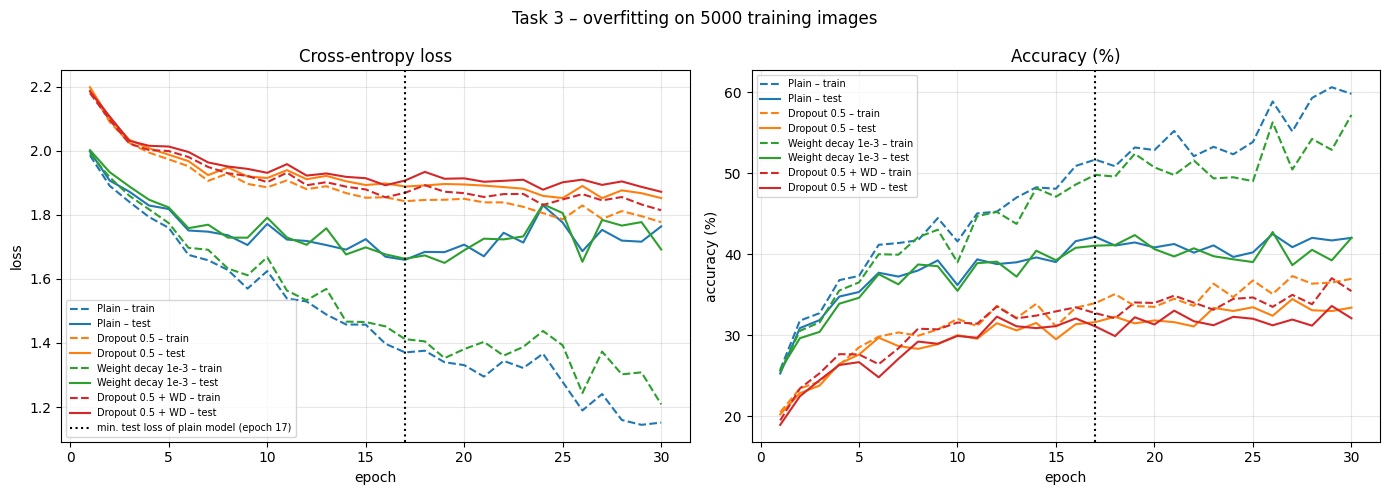

Saved q2_task3_curves.png

Model                   Train acc  Test acc  Gap (pp)  Min test loss  @epoch
----------------------------------------------------------------------------
Plain                      59.80%    42.02%     17.78         1.6597      17
Dropout 0.5                36.96%    33.40%      3.56         1.8523      27
Weight decay 1e-3          57.20%    42.02%     15.18         1.6500      19
Dropout 0.5 + WD           35.44%    32.09%      3.35         1.8720      30


In [21]:
best_epoch = int(np.argmin(results_t3["Plain"]["test_loss"])) + 1
best_loss  = min(results_t3["Plain"]["test_loss"])
print(f"Plain model: smallest test loss {best_loss:.4f} at epoch {best_epoch} "
      f"(final test loss {results_t3['Plain']['test_loss'][-1]:.4f})")

plot_curves(results_t3, f"Task 3 – overfitting on {N_SMALL} training images", "q2_task3_curves.png",
            mark_epoch=best_epoch, mark_label=f"min. test loss of plain model (epoch {best_epoch})")

print(f"\n{'Model':<22}{'Train acc':>11}{'Test acc':>10}{'Gap (pp)':>10}{'Min test loss':>15}{'@epoch':>8}")
print("-" * 76)
for name, h in results_t3.items():
    tr, te = h["train_acc_eval"][-1], h["test_acc"][-1]
    print(f"{name:<22}{tr:>10.2f}%{te:>9.2f}%{tr-te:>10.2f}{min(h['test_loss']):>15.4f}{int(np.argmin(h['test_loss']))+1:>8d}")

### Dropout model with and without `model.eval()`

With `model.eval()` dropout is switched off and the full network is used. Without it the model stays in `train()` mode and dropout keeps zeroing half of the hidden units at test time. These models have no batch norm, so evaluating in `train()` mode does not change any running statistics.

In [23]:
print(f"{'Model':<22}{'Test acc, model.eval()':>25}{'Test acc, train mode':>24}")
print("-" * 71)
for name in ["Dropout 0.5", "Dropout 0.5 + WD"]:
    m = models_t3[name]
    set_seed(SEED)
    _, acc_eval  = evaluate(m, testloader, use_eval=True)
    _, acc_train = evaluate(m, testloader, use_eval=False)
    print(f"{name:<22}{acc_eval:>24.2f}%{acc_train:>23.2f}%")

Model                    Test acc, model.eval()    Test acc, train mode
-----------------------------------------------------------------------
Dropout 0.5                              33.40%                  26.33%
Dropout 0.5 + WD                         32.09%                  26.62%


### Analysis

| Model | Train acc (eval) | Test acc | Gap (pp) | Min. test loss (epoch) | Final test loss |
|---|---|---|---|---|---|
| Plain | 59.80 % | 42.02 % | 17.78 | 1.6597 (17) | 1.7640 |
| Dropout 0.5 | 36.96 % | 33.40 % | 3.56 | 1.8523 (27) | 1.8524 |
| Weight decay 1e-3 | 57.20 % | 42.02 % | 15.18 | 1.6500 (19) | 1.6919 |
| Dropout 0.5 + WD | 35.44 % | 32.09 % | 3.35 | 1.8720 (30) | 1.8720 |

The plain model overfits. Its train accuracy is 17.78 pp above its test accuracy, and its test loss is smallest at epoch 17 (1.6597, dotted line in the figure) and then rises to 1.7640 at epoch 30 while the training set keeps being fitted. The train accuracy is far from 100 %, so this is a growing train/test discrepancy and rising test loss, not memorisation.

Weight decay 1e-3 lowers the minimum test loss slightly (1.6500 at epoch 19) and the final test loss to 1.6919. The test accuracy is the same as the plain model (42.02 %) and the gap is 2.6 pp smaller. The effect is modest.

Dropout 0.5 shrinks the gap to 3.56 pp and the test loss no longer rises, but the test accuracy falls to 33.40 % and the train accuracy is only 36.96 %. With p = 0.5 on hidden layers of 200 and 150 units and only 30 epochs, the network under-fits, so the overfitting disappears because the model learns less. Dropout with weight decay behaves the same way (gap 3.35 pp, test accuracy 32.09 %).

Weight decay was the only regulariser that improved the test loss without lowering the test accuracy. These are single runs, and the best epoch is chosen on the test set as the assignment asks, so the minimum test losses are slightly optimistic.

| Model | Test acc with `model.eval()` | Test acc without it |
|---|---|---|
| Dropout 0.5 | 33.40 % | 26.33 % |
| Dropout 0.5 + WD | 32.09 % | 26.62 % |

Without `model.eval()` the accuracy drops by about 5 to 7 pp, because half of the hidden units are randomly dropped at every forward pass, and it changes from run to run.